| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../7_METODOS_NUMERICOS_PARA_ODE/7_7_Stability.ipynb) | [⏩](../9_METODOS_NUMERICOS_PARA_PDE/9_1_Finite_Difference_Method.ipynb) |

# 8.1 PDE fundamentales: campos, transporte, difusión y ondas

Una PDE relaciona derivadas parciales de un campo como temperatura $u(x,t)$, presión $p(x,y,z)$ o desplazamiento de una membrana. El campo depende de varias variables y las condiciones de frontera forman parte esencial del problema. Estudiaremos clasificación, condiciones iniciales, soluciones analíticas simples y el significado científico de sus diferencias.

Objetivos: interpretar ecuaciones de calor, advección, onda y Poisson; reconocer unidades y condiciones necesarias; estudiar conservación y suavizado; plantear un ejemplo inverso de difusividad. Las primeras gráficas usan soluciones exactas, evitando confundir todavía física y discretización.

Este cuaderno se ejecuta de arriba abajo y genera todos los datos localmente. Los ejemplos son unidimensionales salvo un experimento 2D pequeño. Se necesitan cálculo multivariable, ecuaciones diferenciales y álgebra lineal. La sencillez de la geometría permite concentrarse en formulación, error, estabilidad y propiedades físicas.

## 1. Campo, operadores y orden

Para $u(x,t)$, $u_t$ mide cambio temporal local y $u_x$ cambio espacial. En varias dimensiones, $\nabla u$ es el gradiente y $\Delta u=\sum_j u_{x_jx_j}$ el laplaciano. El orden de una PDE es el de la derivada de mayor orden que aparece.

Una PDE es lineal si el operador sobre $u$ es lineal: $L(au+bv)=aL(u)+bL(v)$. El calor con difusividad constante es lineal; $u_t+u u_x=0$ es no lineal. Una fuente conocida $f(x,t)$ no destruye linealidad. Coeficientes dependientes de $u$ sí pueden hacerlo.

No basta escribir una ecuación. Debe especificarse dominio $\Omega$, intervalo temporal, fronteras, estado inicial y parámetros. Si alguno falta, el problema puede tener múltiples soluciones o no ser compatible.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.sparse.linalg import spsolve
from scipy.optimize import minimize_scalar
plt.rcParams.update({"figure.figsize":(9,4),"axes.grid":True,"font.size":11})
np.set_printoptions(precision=6,suppress=True)

## 2. Clasificación de segundo orden

En dos variables, considera la parte principal $A u_{xx}+2B u_{xy}+C u_{yy}$. El discriminante $B^2-AC$ distingue tipo elíptico si es negativo, parabólico si es cero e hiperbólico si es positivo, bajo las hipótesis de esta clasificación local.

Poisson $u_{xx}+u_{yy}=f$ es elíptica: describe equilibrio. El calor $u_t=\alpha u_{xx}$ es parabólica: describe difusión y necesita un dato inicial. La onda $u_{tt}=c^2u_{xx}$ es hiperbólica: requiere desplazamiento y velocidad inicial. La advección $u_t+c u_x=0$ es de primer orden y se estudia mediante características.

La clasificación orienta propagación de información y condiciones; no reemplaza un análisis de bien planteamiento en geometrías y fronteras concretas.

## 3. Condiciones iniciales y de frontera

Una condición **Dirichlet** prescribe $u=g$ en la frontera. Una **Neumann** prescribe derivada normal o flujo; debe aclararse qué convención de signo se usa. Una **Robin** combina valor y flujo, como intercambio convectivo. La periodicidad identifica extremos de un dominio.

Para calor en $[0,L]$ se necesita $u(x,0)=u_0(x)$ y condiciones en ambos extremos. Para advección con $c>0$ en un intervalo abierto, la información entra por el extremo izquierdo: imponer datos arbitrarios también a la salida puede sobredeterminar el problema. Para Poisson con Neumann en toda la frontera existe una condición de compatibilidad de la fuente y la solución queda determinada solo hasta una constante.

Comprueba compatibilidad en la esquina tiempo–frontera: si el estado inicial tiene valor distinto del Dirichlet a $t=0$, puede aparecer una capa o pérdida de regularidad.

## 4. Difusión: la ecuación del calor

El calor en una barra con difusividad $\alpha>0$ satisface
$$u_t=\alpha u_{xx}.$$
La unidad de $\alpha$ es longitud$^2$/tiempo. Con extremos a cero y condición inicial $\sin(\pi x/L)$,
$$u(x,t)=e^{-\alpha(\pi/L)^2t}\sin(\pi x/L).$$
La forma espacial se conserva mientras decae la amplitud. Un modo de frecuencia $m$ decae con velocidad proporcional a $m^2$: las estructuras finas se suavizan más rápido.

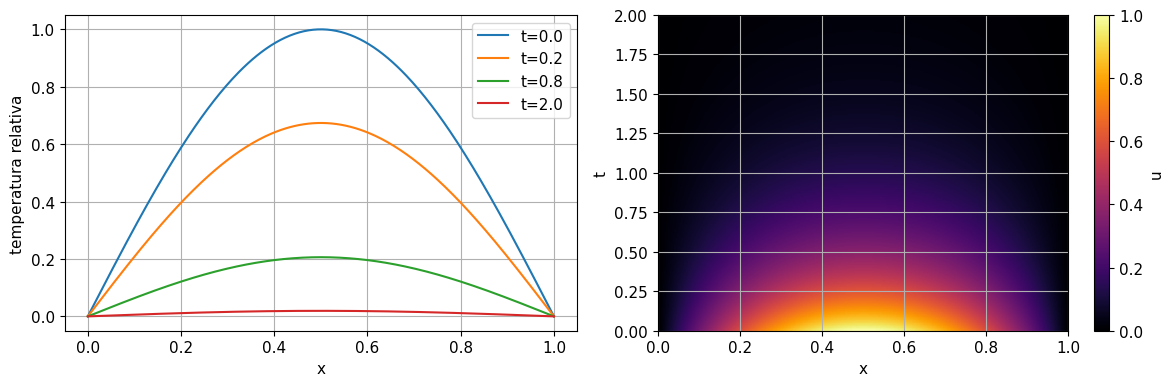

In [2]:
L,alpha=1.,0.2
x=np.linspace(0,L,301); times=np.linspace(0,2,201)
U=np.exp(-alpha*(np.pi/L)**2*times[:,None])*np.sin(np.pi*x/L)[None,:]
fig,ax=plt.subplots(1,2,figsize=(12,4))
for time in [0.,0.2,0.8,2.]:
    ax[0].plot(x,np.exp(-alpha*np.pi**2*time)*np.sin(np.pi*x),label=f"t={time}")
ax[0].set(xlabel="x",ylabel="temperatura relativa"); ax[0].legend()
im=ax[1].imshow(U,origin="lower",aspect="auto",extent=[0,L,0,2],cmap="inferno")
ax[1].set(xlabel="x",ylabel="t"); fig.colorbar(im,ax=ax[1],label="u")
plt.tight_layout(); plt.show()

**Interpretación del experimento.** La amplitud cae sin desplazarse. Con Dirichlet cero, la barra intercambia calor con sus extremos: su integral espacial no tiene por qué conservarse. Con fronteras aisladas, el balance sería diferente.

## 5. Advección: transportar sin suavizar

En $u_t+c u_x=0$, las características son $x(t)=x_0+ct$ y $u$ permanece constante sobre ellas. Por tanto,
$$u(x,t)=u_0(x-ct).$$
Con dominio periódico de longitud $L$, se interpreta $x-ct$ módulo $L$. En la ecuación continua la forma y amplitud se preservan; un esquema numérico puede introducir difusión o dispersión artificial.

La velocidad $c$ tiene unidades longitud/tiempo. Si cambia de signo, cambia también el lado por donde entra la información.

Periodo temporal de una vuelta: 2.5


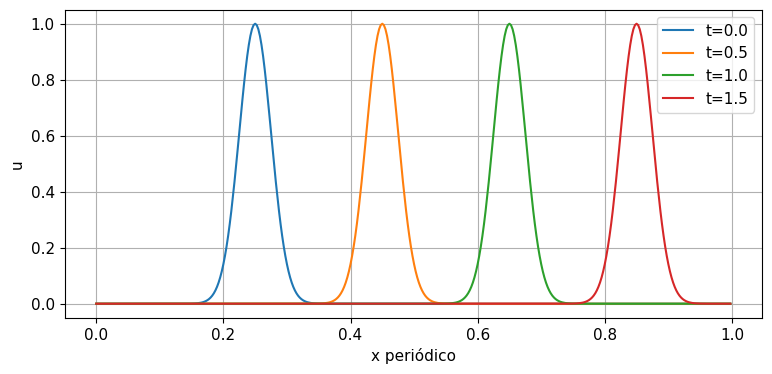

In [3]:
L,c_speed=1.,0.4
x=np.linspace(0,L,400,endpoint=False)
initial=lambda z:np.exp(-80*(np.sin(np.pi*(z-0.25)))**2)
for time in [0.,0.5,1.,1.5]:
    plt.plot(x,initial((x-c_speed*time)%L),label=f"t={time}")
plt.xlabel("x periódico"); plt.ylabel("u"); plt.legend(); plt.show()
print("Periodo temporal de una vuelta:",L/c_speed)

**Interpretación del experimento.** El perfil se traslada y vuelve a aparecer por el extremo opuesto. El dominio periódico modela un anillo; no representa una frontera abierta ni una pared impermeable.

## 6. Onda: propagación en dos direcciones

En una cuerda,
$$u_{tt}=c^2u_{xx}.$$
La solución general en la recta es $F(x-ct)+G(x+ct)$. Para desplazamiento inicial $u_0$ y velocidad inicial cero, resulta $u=[u_0(x-ct)+u_0(x+ct)]/2$. Un pulso inicial se separa en dos: la segunda derivada temporal requiere dos datos iniciales.

En extremos fijos, los modos $\sin(m\pi x/L)$ oscilan en tiempo como $\cos(cm\pi t/L)$; no decaen en la ecuación ideal sin amortiguación. La energía contiene tanto velocidad como deformación espacial.

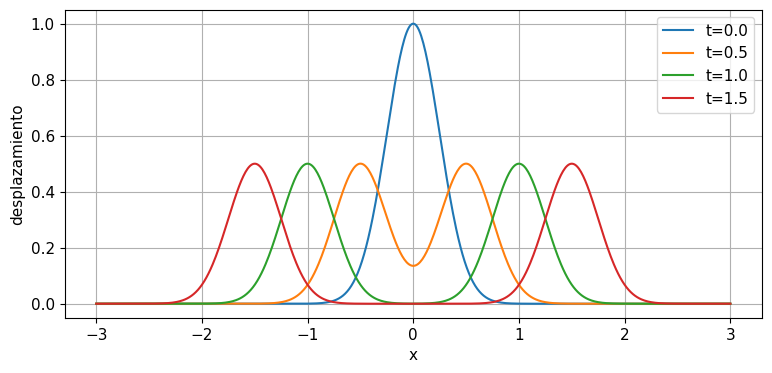

In [4]:
x=np.linspace(-3,3,600); speed=1.
pulse=lambda z:np.exp(-8*z*z)
for time in [0.,0.5,1.,1.5]:
    u=0.5*(pulse(x-speed*time)+pulse(x+speed*time))
    plt.plot(x,u,label=f"t={time}")
plt.xlabel("x"); plt.ylabel("desplazamiento"); plt.legend(); plt.show()

**Interpretación del experimento.** Los dos pulsos tienen amplitud mitad porque la velocidad inicial era cero. La cuerda aquí se considera infinita dentro de los tiempos mostrados: no hay reflexiones de fronteras en el ejemplo analítico.

## 7. Poisson: equilibrio espacial

La forma $-u_{xx}=f(x)$ en $[0,1]$, con $u(0)=u(1)=0$, puede representar equilibrio de temperatura con fuentes o potencial. Si $f=\pi^2\sin(\pi x)$, la solución es $u=\sin(\pi x)$.

Discretizamos la segunda derivada para obtener un sistema tridiagonal. Esto conecta el problema continuo con álgebra lineal: resolver $Au=b$ es una parte del método, y el error espacial permanece incluso si el sistema se resuelve a precisión de máquina.

Error máximo: 0.0005142004781497622
Residual lineal: 4.689582056016661e-13


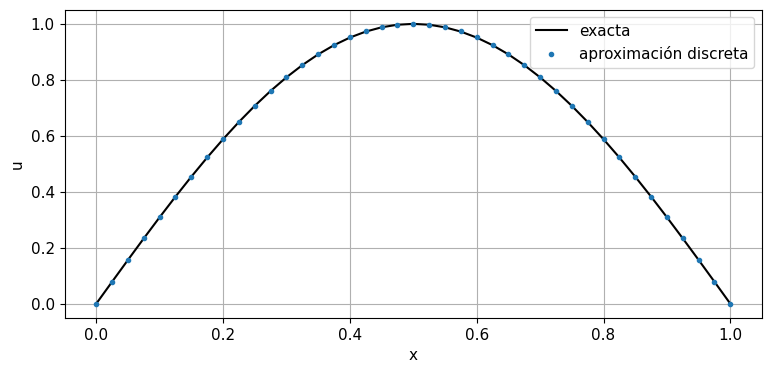

In [5]:
n=40; x=np.linspace(0,1,n+1); h=1/n
A=sparse.diags([-np.ones(n-2),2*np.ones(n-1),-np.ones(n-2)],[-1,0,1],format="csr")/h**2
rhs=np.pi**2*np.sin(np.pi*x[1:-1])
u=np.zeros(n+1); u[1:-1]=spsolve(A,rhs)
plt.plot(x,np.sin(np.pi*x),"k",label="exacta")
plt.plot(x,u,"o",markersize=3,label="aproximación discreta")
plt.xlabel("x"); plt.ylabel("u"); plt.legend(); plt.show()
print("Error máximo:",np.max(abs(u-np.sin(np.pi*x))))
print("Residual lineal:",np.linalg.norm(A@u[1:-1]-rhs,np.inf))

**Interpretación del experimento.** El residual lineal puede ser mucho menor que el error frente a la solución continua. Son métricas de cosas diferentes: exactitud de la resolución algebraica y exactitud de la discretización.

## 8. Conservación y balances integrales

Para una ley $u_t+\nabla\cdot F=s$, integrar sobre un volumen y usar el teorema de divergencia da
$$\frac{d}{dt}\int_\Omega u\,dx=-\int_{\partial\Omega}F\cdot n\,dS+\int_\Omega s\,dx.$$
La cantidad cambia por flujos de frontera y fuentes. En advección periódica sin fuentes, la masa se conserva. Para calor, $F=-\alpha\nabla u$ y fronteras Neumann homogéneas producen conservación del promedio.

No toda integral es una masa conservada. En calor con fronteras compatibles, la energía cuadrática suele decrecer:
$$\frac d{dt}\frac12\int u^2dx=-\alpha\int |\nabla u|^2dx\le0.$$
Esta identidad explica suavizado y proporciona un control físico del solver.

## 9. Difusión y pérdida de información de alta frecuencia

Con $u_0=\sin(\pi x)+0.3\sin(8\pi x)$, el segundo modo decae 64 veces más rápido en su exponente. Resolver hacia delante es estable, pero reconstruir el estado inicial desde una observación tardía requiere amplificar factores exponenciales y también amplifica ruido.

Este es un problema inverso mal condicionado. Tener una ecuación conocida no elimina la necesidad de regularización e incertidumbre al inferir entradas pasadas.

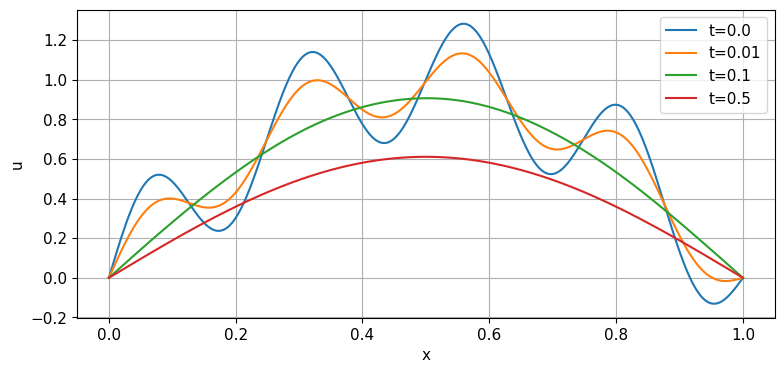

In [6]:
x=np.linspace(0,1,600); alpha=0.1
for time in [0.,0.01,0.1,0.5]:
    u=np.exp(-alpha*np.pi**2*time)*np.sin(np.pi*x)+0.3*np.exp(-alpha*(8*np.pi)**2*time)*np.sin(8*np.pi*x)
    plt.plot(x,u,label=f"t={time}")
plt.xlabel("x"); plt.ylabel("u"); plt.legend(); plt.show()

**Interpretación del experimento.** Los detalles rápidos desaparecen mucho antes que la forma global. Una red que intenta invertir difusión desde datos tardíos tendrá que usar supuestos adicionales, pues las observaciones ya no contienen todas las frecuencias con buena relación señal–ruido.

## 10. Estimar difusividad desde sensores

Si el campo es un único modo y conocemos la amplitud inicial, el sensor del centro registra $u(1/2,t)=e^{-\alpha\pi^2t}$. Ajustamos $\alpha$ a varias observaciones generadas con ruido.

La identificabilidad depende de tiempos y posiciones: un sensor en un extremo Dirichlet cero no aporta información de este parámetro. También hay confusión si amplitud inicial y difusividad se estiman con un único dato.

Alpha verdadero: 0.15 Estimado: 0.1494879840442717


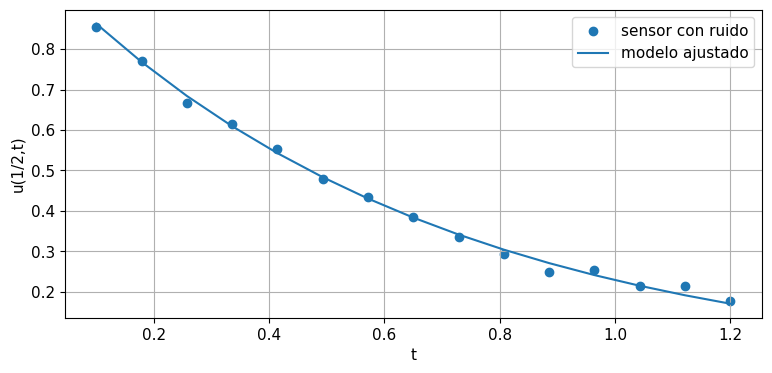

In [7]:
rng=np.random.default_rng(9); alpha_true=0.15
sensor_times=np.linspace(0.1,1.2,15)
observed=np.exp(-alpha_true*np.pi**2*sensor_times)+rng.normal(0,0.01,len(sensor_times))
objective=lambda a:np.sum((np.exp(-a*np.pi**2*sensor_times)-observed)**2)
fit=minimize_scalar(objective,bounds=(0.01,0.5),method="bounded")
plt.scatter(sensor_times,observed,label="sensor con ruido")
plt.plot(sensor_times,np.exp(-fit.x*np.pi**2*sensor_times),label="modelo ajustado")
plt.xlabel("t"); plt.ylabel("u(1/2,t)"); plt.legend(); plt.show()
print("Alpha verdadero:",alpha_true,"Estimado:",fit.x)

**Interpretación del experimento.** El ajuste ilustra inferencia de un coeficiente físico; no es una PINN ni cuantifica por sí mismo incertidumbre. Repite con varias semillas o ajusta un modelo estadístico para estudiar precisión del parámetro.

## 11. Bien planteamiento y elección de modelo

Un problema bien planteado tiene solución, unicidad y dependencia continua de los datos en espacios apropiados. La difusión hacia atrás puede violar la estabilidad frente a ruido; Poisson con Neumann necesita compatibilidad; la onda requiere dos estados iniciales.

Antes de programar, dibuja el dominio y marca qué información entra por cada frontera. Escribe unidades, signos de fuentes y flujos. Después decide si el modelo admite discontinuidades, ondas o suavizado. No emplees una ley de difusión para transportar un pulso esperando que conserve su forma: ese comportamiento sería incompatible con la física de la ecuación.

## 12. Verificación, validación y vínculo con SciML

Una **verificación** pregunta si resolvemos correctamente las ecuaciones que elegimos: compara soluciones exactas, realiza refinamiento de malla, mide residual y observa propiedades discretas. Una **validación física** compara el modelo con mediciones independientes y sus incertidumbres. Un método numérico puede estar perfectamente verificado y aun así representar una ley física inadecuada.

Para fabricar una solución conocida, elige $u_*$, sustitúyela en la PDE y deriva la fuente y las fronteras correspondientes. Al ejecutar el solver, compara con $u_*$ en una norma definida. Este método detecta signos, índices y condiciones de frontera mal implementados; no prueba por sí solo desempeño en todo problema.

Si los campos numéricos se usan para entrenar un operador neuronal, documenta malla, paso temporal, condiciones de frontera, precisión del solver y distribución de parámetros. Reserva casos de prueba y compara también resoluciones no vistas. Un modelo aprendido puede reproducir el sesgo de discretización de sus etiquetas; una métrica sobre la misma malla no revela necesariamente ese problema.

Una PINN utiliza residuales de una PDE, pero también necesita satisfacer datos iniciales y de frontera. Un residual pequeño en pocos puntos no garantiza un campo preciso entre ellos. Compara contra una solución numérica refinada, revisa balances y calcula una norma sobre una malla de evaluación independiente. Las distintas formulaciones de residual, fuerte e integral, aportan criterios científicos diferentes.

| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../7_METODOS_NUMERICOS_PARA_ODE/7_7_Stability.ipynb) | [⏩](../9_METODOS_NUMERICOS_PARA_PDE/9_1_Finite_Difference_Method.ipynb) |